In [17]:
import pandas as pd

def nettoyer_dvf_final(chemin_fichier):
    print(f"Traitement de {chemin_fichier}...")
    
    # 1. Chargement (Types forcés pour éviter le DtypeWarning)
    types_cols = {
        'Code departement': str, 
        'Code commune': str,
        'Type local': 'category' # Optimisation mémoire très pertinente
    }

    df = pd.read_csv(
        chemin_fichier, 
        sep='|', 
        decimal=',',
        usecols=[
            'Valeur fonciere', 'Date mutation', 'Nature mutation', 
            'Code departement', 'Code commune', 'Type local', 'Surface reelle bati'
        ],
        dtype=types_cols
    )
    
    # 2. RENOMMAGE SÉCURISÉ
    nom_cols = {
        'Valeur fonciere': 'valeur',
        'Date mutation': 'date',
        'Nature mutation': 'nature',
        'Code departement': 'dept',
        'Code commune': 'commune_insee',
        'Type local': 'type_local',
        'Surface reelle bati': 'surface'
    }
    df = df.rename(columns=nom_cols)

    # 3. FILTRES STRICTS ET PURGE DES CATÉGORIES
    # On ne garde que Ventes et Maison/Appart
    df = df[
        (df['nature'] == 'Vente') & 
        (df['type_local'].isin(['Maison', 'Appartement']))
    ]
    
    # LA CORRECTION EST ICI : On purge les catégories vides de la mémoire
    df['type_local'] = df['type_local'].cat.remove_unused_categories()
    
    # 4. GESTION DES CODES INSEE
    df = df.dropna(subset=['dept', 'commune_insee'])
    df['code_insee'] = df['dept'] + df['commune_insee'].str.zfill(3)

    # 5. NETTOYAGE VALEURS
    df['surface'] = pd.to_numeric(df['surface'], errors='coerce')
    df['valeur'] = pd.to_numeric(df['valeur'], errors='coerce')
    
    df = df.dropna(subset=['surface', 'valeur'])
    df = df[(df['surface'] > 9) & (df['valeur'] > 1000)]
    
    # 6. CALCUL
    df['prix_m2'] = df['valeur'] / df['surface']
    df = df[df['prix_m2'] < 30000] # On retire les aberrations > 30k€/m2
    
    print(f"-> Succès : {len(df)} transactions purifiées récupérées.")
    return df

In [18]:
import pandas as pd
vf_2021=nettoyer_dvf_final('/home/ensai/Téléchargements/proj_stat/data/ValeursFoncieres-2021.txt')
vf_2022=nettoyer_dvf_final('/home/ensai/Téléchargements/proj_stat/data/ValeursFoncieres-2022.txt')
vf_2023=nettoyer_dvf_final('/home/ensai/Téléchargements/proj_stat/data/ValeursFoncieres-2023.txt')
vf_2024=nettoyer_dvf_final('/home/ensai/Téléchargements/proj_stat/data/ValeursFoncieres-2024.txt')
vf_2021.head(10)
# 1. On s'assure d'avoir l'année dans chaque tableau
# (Adaptez les noms df_2021, df_2022 selon vos variables à vous)

# Exemple pour 2021
vf_2021['date'] = pd.to_datetime(vf_2021['date'], dayfirst=True)
vf_2021['annee'] = 2021

#Exemple pour 2022 (si vous l'avez chargé)
vf_2022['date'] = pd.to_datetime(vf_2022['date'], dayfirst=True)
vf_2022['annee'] = 2022
vf_2023['date'] = pd.to_datetime(vf_2023['date'], dayfirst=True)
vf_2023['annee'] = 2023
vf_2024['date'] = pd.to_datetime(vf_2024['date'], dayfirst=True)
vf_2024['annee'] = 2024

# 2. On colle tout verticalement
# Mettez la liste de TOUTES vos variables ci-dessous
liste_tableaux = [vf_2021,vf_2022,vf_2023,vf_2024] # Ajoutez les autres ici : [vf_2020, vf_2021, vf_2022...]

vf_total = pd.concat(liste_tableaux)

print(f"Total transactions assemblées : {len(vf_total)}")

Traitement de /home/ensai/Téléchargements/proj_stat/data/ValeursFoncieres-2021.txt...
-> Succès : 1395447 transactions purifiées récupérées.
Traitement de /home/ensai/Téléchargements/proj_stat/data/ValeursFoncieres-2022.txt...
-> Succès : 1327218 transactions purifiées récupérées.
Traitement de /home/ensai/Téléchargements/proj_stat/data/ValeursFoncieres-2023.txt...
-> Succès : 1043813 transactions purifiées récupérées.
Traitement de /home/ensai/Téléchargements/proj_stat/data/ValeursFoncieres-2024.txt...
-> Succès : 941687 transactions purifiées récupérées.
Total transactions assemblées : 4708165


In [58]:
import pandas as pd

def generer_stats_attrition_dvf(chemin_fichier):
    print(f"--- LECTURE DU FICHIER : {chemin_fichier} ---")
    
    # Dictionnaire pour stocker le nombre de lignes à chaque étape
    stats = {}
    
    # 1. Chargement optimisé
    types_cols = {
        'Code departement': str, 
        'Code commune': str,
        'Type local': 'category'
    }

    df = pd.read_csv(
        chemin_fichier, 
        sep='|', 
        decimal=',',
        usecols=[
            'Valeur fonciere', 'Date mutation', 'Nature mutation', 
            'Code departement', 'Code commune', 'Type local', 'Surface reelle bati'
        ],
        dtype=types_cols,
        low_memory=False
    )
    
    # ÉTAPE 1 : Données brutes
    stats['1. Base DVF brute initiale'] = len(df)
    
    # Renommage sécurisé
    nom_cols = {
        'Valeur fonciere': 'valeur', 'Date mutation': 'date', 'Nature mutation': 'nature',
        'Code departement': 'dept', 'Code commune': 'commune_insee',
        'Type local': 'type_local', 'Surface reelle bati': 'surface'
    }
    df = df.rename(columns=nom_cols)

    # 2. Filtres stricts (Vente + Maison/Appartement)
    df = df[(df['nature'] == 'Vente') & (df['type_local'].isin(['Maison', 'Appartement']))]
    df['type_local'] = df['type_local'].cat.remove_unused_categories()
    stats['2. Filtre "Vente" + Maisons/Appartements'] = len(df)

    # 3. Purge géographique
    df = df.dropna(subset=['dept', 'commune_insee'])
    df['code_insee'] = df['dept'] + df['commune_insee'].str.zfill(3)
    stats['3. Suppression géographie manquante (NA)'] = len(df)

    # 4. Cohérence physique et financière (Surfaces et valeurs)
    df['surface'] = pd.to_numeric(df['surface'], errors='coerce')
    df['valeur'] = pd.to_numeric(df['valeur'], errors='coerce')
    df = df.dropna(subset=['surface', 'valeur'])
    df = df[(df['surface'] > 9) & (df['valeur'] > 1000)]
    stats['4. Filtres surface > 9m2 et valeur > 1000€'] = len(df)
    
    # 5. Aberrations de prix (Trimming)
    df['prix_m2'] = df['valeur'] / df['surface']
    df = df[df['prix_m2'] < 30000]
    stats['5. Trimming (prix au m2 < 30 000€)'] = len(df)
    
    # ---------------------------------------------------------
    # BASCULE MICRO -> MACRO (La vraie structure de ton modèle)
    # ---------------------------------------------------------
    df['annee'] = pd.to_datetime(df['date'], format='%d/%m/%Y').dt.year
    
    df_macro = df.groupby(['code_insee', 'annee']).agg(
        prix_m2_median=('prix_m2', 'median'),
        nb_ventes=('valeur', 'count'),
        surface_moyenne=('surface', 'mean')
    ).reset_index()
    
    # ÉTAPE FINALE : Panel agrégé
    stats['6. Agrégation spatio-temporelle (Commune-Année)'] = len(df_macro)

    # --- AFFICHAGE PROPRE DANS LA CONSOLE ---
    print("\n" + "="*70)
    print(" RÉSULTATS POUR L'ANNEXE A (TABLEAU D'ATTRITION) ")
    print("="*70)
    
    total_initial = stats['1. Base DVF brute initiale']
    
    for etape, nb_lignes in stats.items():
        if "Agrégation" in etape:
            print("-" * 70) # Séparateur visuel avant le passage au macro
            pct = "N/A" # Le pourcentage n'a plus de sens mathématique ici car on change d'unité
            print(f"{etape:<45} | {nb_lignes:>10} | {pct:>7}")
        else:
            pct = f"{(nb_lignes / total_initial) * 100:.1f} %"
            print(f"{etape:<45} | {nb_lignes:>10} | {pct:>7}")
        
    print("="*70 + "\n")
    
    return df_macro

# Commande à lancer (remplace par le chemin de ton fichier ou ta boucle) :
# df_final = generer_stats_attrition_dvf("chemin/vers/ton/fichier_dvf.csv")

In [59]:
generer_stats_attrition_dvf('/home/ensai/Téléchargements/proj_stat/data/ValeursFoncieres-2021.txt')

--- LECTURE DU FICHIER : /home/ensai/Téléchargements/proj_stat/data/ValeursFoncieres-2021.txt ---

 RÉSULTATS POUR L'ANNEXE A (TABLEAU D'ATTRITION) 
1. Base DVF brute initiale                    |    4674176 | 100.0 %
2. Filtre "Vente" + Maisons/Appartements      |    1472336 |  31.5 %
3. Suppression géographie manquante (NA)      |    1472336 |  31.5 %
4. Filtres surface > 9m2 et valeur > 1000€    |    1455924 |  31.1 %
5. Trimming (prix au m2 < 30 000€)            |    1395447 |  29.9 %
----------------------------------------------------------------------
6. Agrégation spatio-temporelle (Commune-Année) |      31745 |     N/A



,code_insee,annee,prix_m2_median,nb_ventes,surface_moyenne
0,01001,2021,2539.932111,14,118.000000
1,01002,2021,3600.000000,7,115.714286
2,01004,2021,2321.764706,322,82.959627
3,01005,2021,3263.157895,33,97.090909
4,01006,2021,1550.747348,8,101.375000
...,...,...,...,...,...
31740,974020,2021,2469.135802,121,85.892562
31741,974021,2021,1306.953193,30,101.533333
31742,974022,2021,2230.158730,828,79.625604
31743,974023,2021,2263.888889,28,68.857143


In [13]:
vf_total.head()
vf_total.to_csv('/home/ensai/Téléchargements/proj_stat/data/vf_total.csv', index=False) # Sauvegarde du total assemblé

In [19]:
# 3. NOUVEAU : On groupe par Commune, Année ET Type de Local
vf_final_immo = vf_total.groupby(['code_insee', 'annee', 'type_local']).agg({
    'prix_m2': 'median',       # Le prix médian par type de bien
    'valeur': 'count',         # Le volume par type de bien
    'surface': 'mean'          # La surface moyenne par type de bien
}).reset_index()

# 4. On renomme proprement
vf_final_immo.columns = ['code_insee', 'annee', 'type_local', 'prix_m2_median', 'nb_ventes', 'surface_moy']

# 5. Aperçu du résultat final
vf_final_immo.head(20)

/tmp/ipykernel_150406/1891334975.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  vf_final_immo = vf_total.groupby(['code_insee', 'annee', 'type_local']).agg({


,code_insee,annee,type_local,prix_m2_median,nb_ventes,surface_moy
0,01001,2021,Appartement,NaN,0,NaN
1,01001,2021,Maison,2539.932111,14,118.000000
2,01001,2022,Appartement,NaN,0,NaN
3,01001,2022,Maison,2812.500000,13,125.230769
4,01001,2023,Appartement,NaN,0,NaN
5,01001,2023,Maison,2345.132743,15,110.600000
6,01001,2024,Appartement,NaN,0,NaN
7,01001,2024,Maison,3212.087912,5,95.200000
8,01002,2021,Appartement,4090.909091,3,107.666667
9,01002,2021,Maison,1346.850649,4,121.750000


In [16]:
import pandas as pd
import numpy as np

# Remplacer 'df' par le nom de ton dataframe actuel (ex: df_dvf)
df_a_tester = vf_final_immo.copy() 

print("=== 1. AUDIT STRICT DES VALEURS MANQUANTES ===")
# Calcul du nombre et du pourcentage de NaN par colonne
total_lignes = len(df_a_tester)
valeurs_manquantes = df_a_tester.isna().sum()
pourcentage_manquant = (valeurs_manquantes / total_lignes) * 100

audit_nan = pd.DataFrame({
    'Nb_Manquants': valeurs_manquantes,
    'Pourcentage (%)': pourcentage_manquant.round(2)
})
# On ne garde que les colonnes qui ont au moins un trou, triées par gravité
audit_nan = audit_nan[audit_nan['Nb_Manquants'] > 0].sort_values(by='Pourcentage (%)', ascending=False)

if audit_nan.empty:
    print("✅ Parfait : Aucune valeur manquante détectée dans le DataFrame.")
else:
    print("⚠️ ALERTE : Voici les colonnes contenant des valeurs manquantes :")
    print(audit_nan)

print("\n=== 2. STATISTIQUES DESCRIPTIVES (Variables Numériques) ===")
# On génère les stats uniquement sur les données présentes
stats_desc = df_a_tester.describe().T
stats_desc = stats_desc[['count', 'mean', 'std', 'min', '50%', 'max']]
stats_desc.columns = ['Volume (N)', 'Moyenne', 'Ecart-Type', 'Minimum', 'Médiane', 'Maximum']
print(stats_desc.round(2))

print("\n=== 3. STATISTIQUES DESCRIPTIVES (Variables Catégorielles) ===")
# Pour vérifier la répartition Maisons / Appartements
if 'type_local' in df_a_tester.columns:
    repartition_type = df_a_tester['type_local'].value_counts(dropna=False)
    pct_type = df_a_tester['type_local'].value_counts(normalize=True, dropna=False) * 100
    
    repartition_df = pd.DataFrame({
        'Volume': repartition_type,
        'Pourcentage (%)': pct_type.round(2)
    })
    print(repartition_df)
else:
    print("La colonne 'type_local' n'est pas présente.")

=== 1. AUDIT STRICT DES VALEURS MANQUANTES ===
⚠️ ALERTE : Voici les colonnes contenant des valeurs manquantes :
                Nb_Manquants  Pourcentage (%)
prix_m2_median        100177             37.7
surface_moy           100177             37.7

=== 2. STATISTIQUES DESCRIPTIVES (Variables Numériques) ===
                Volume (N)  Moyenne  Ecart-Type  Minimum  Médiane   Maximum
annee             265744.0  2022.50        1.12  2021.00  2022.50   2024.00
prix_m2_median    165567.0  2236.45     1774.53     3.96  1845.36  29801.32
nb_ventes         265744.0    17.72      101.15     0.00     3.00   9813.00
surface_moy       165567.0    94.80       32.04    10.00    95.50    880.00

=== 3. STATISTIQUES DESCRIPTIVES (Variables Catégorielles) ===
             Volume  Pourcentage (%)
type_local                          
Appartement  132872             50.0
Maison       132872             50.0


In [ ]:
df_dynamique = pd.read_csv('/home/ensai/Téléchargements/proj_stat/notebooks/df_reg_dynamique.csv')


In [46]:
import pandas as pd
import numpy as np

print("=== 1. SÉCURISATION DES CODES INSEE ET NETTOYAGE DVF ===")
# On force le code INSEE en texte à 5 caractères (ex: '01004') pour que la fusion soit parfaite
vf_final_immo['code_insee'] = vf_final_immo['code_insee'].astype(str).str.zfill(5)
df_dynamique['code_insee'] = df_dynamique['code_insee'].astype(str).str.zfill(5)

# On supprime les lignes "fantômes" générées par Pandas là où il n'y a eu aucune vente (les NaN)
df_dvf_propre = vf_final_immo.dropna(subset=['prix_m2_median', 'nb_ventes']).copy()
print(f"Lignes DVF réelles (sans les fantômes) : {len(df_dvf_propre)}")

print("\n=== 2. FUSION INTELLIGENTE ===")
colonnes_contexte = [
    'code_insee', 'annee', 'aggravation_eau', 'aggravation_secheresse', 
    'marin_10a', 'atmo_10a', 'marin_littoral_inter', 'mvt_10a', 'est_littoral', 'revenu_median'
]

df_risques_purs = df_dynamique[colonnes_contexte].drop_duplicates(subset=['code_insee', 'annee'])

df_finale = pd.merge(
    df_dvf_propre, 
    df_risques_purs, 
    on=['code_insee', 'annee'], 
    how='left'
)

# On vérifie la perte
lignes_avant = len(df_finale)
df_finale = df_finale.dropna(subset=['revenu_median']) 
print(f"Lignes fusionnées : {lignes_avant} -> Seulement {lignes_avant - len(df_finale)} lignes perdues (Normal).")


print("\n=== 3. STATISTIQUES DESCRIPTIVES POUR LE MÉMOIRE ===")
# On applique ton fameux filtre de 10 ventes minimum pour un prix robuste
df_stats = df_finale[df_finale['nb_ventes'] >= 10].copy()
print(f"Taille de l'échantillon final (>= 10 ventes) : {len(df_stats)} observations.\n")

# Variables continues
cols_continues = ['prix_m2_median', 'surface_moy', 'revenu_median', 'marin_10a', 'atmo_10a']
stats_continues = df_stats[cols_continues].describe().T
stats_continues = stats_continues[['count', 'mean', 'std', 'min', 'max']]
stats_continues.columns = ['N', 'Moyenne', 'Écart-Type', 'Min', 'Max']
print("--- VARIABLES CONTINUES ---")
print(stats_continues.round(2))

# Variables binaires
print("\n--- VARIABLES BINAIRES (Proportions en %) ---")
print("\nRépartition Maisons / Appartements :")
print(df_stats['type_local'].value_counts(normalize=True).round(3) * 100)

print("\nPart des observations sur le littoral (%) :")
print(df_stats['est_littoral'].value_counts(normalize=True).round(3) * 100)

print("\nPart des observations ayant subi une AGGRAVATION Inondation (%) :")
print(df_stats['aggravation_eau'].value_counts(normalize=True).round(3) * 100)

print("\nPart des observations ayant subi une AGGRAVATION Sécheresse (%) :")
print(df_stats['aggravation_secheresse'].value_counts(normalize=True).round(3) * 100)

=== 1. SÉCURISATION DES CODES INSEE ET NETTOYAGE DVF ===
Lignes DVF réelles (sans les fantômes) : 165567

=== 2. FUSION INTELLIGENTE ===
Lignes fusionnées : 165567 -> Seulement 12533 lignes perdues (Normal).

=== 3. STATISTIQUES DESCRIPTIVES POUR LE MÉMOIRE ===
Taille de l'échantillon final (>= 10 ventes) : 75191 observations.

--- VARIABLES CONTINUES ---
                      N   Moyenne  Écart-Type       Min       Max
prix_m2_median  75191.0   2440.73     1598.48     21.17  29166.67
surface_moy     75191.0     95.16       25.17     10.00    325.46
revenu_median   75191.0  23355.52     3422.75  13230.00  55340.00
marin_10a       75191.0      0.02        0.21      0.00      5.00
atmo_10a        75191.0      0.00        0.02      0.00      2.00

--- VARIABLES BINAIRES (Proportions en %) ---

Répartition Maisons / Appartements :
type_local
Maison         80.2
Appartement    19.8
Name: proportion, dtype: float64

Part des observations sur le littoral (%) :
est_littoral
0.0    93.0
1.0    

In [47]:
df_finale.head(10)

,code_insee,annee,type_local,prix_m2_median,nb_ventes,surface_moy,aggravation_eau,aggravation_secheresse,marin_10a,atmo_10a,marin_littoral_inter,mvt_10a,est_littoral,revenu_median
0,01001,2021,Maison,2539.932111,14,118.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,25820.0
1,01001,2022,Maison,2812.500000,13,125.230769,0.0,0.0,0.0,0.0,0.0,0.0,0.0,25820.0
2,01001,2023,Maison,2345.132743,15,110.600000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,25820.0
3,01001,2024,Maison,3212.087912,5,95.200000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,25820.0
4,01002,2021,Appartement,4090.909091,3,107.666667,0.0,0.0,0.0,0.0,0.0,0.0,0.0,24480.0
5,01002,2021,Maison,1346.850649,4,121.750000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,24480.0
6,01002,2022,Maison,2359.223301,3,135.333333,0.0,0.0,0.0,0.0,0.0,0.0,0.0,24480.0
7,01002,2023,Appartement,3000.000000,1,30.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,24480.0
8,01002,2023,Maison,1451.612903,3,105.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,24480.0
9,01002,2024,Maison,1941.558442,2,140.500000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,24480.0


In [48]:
df_finale.to_csv('/home/ensai/Téléchargements/proj_stat/data/base_maison_appart .csv', index=False) 

In [49]:
import pandas as pd
import numpy as np

print("=== 1. PURIFICATION STRICTE DE LA BASE ===")
# On applique la règle d'or : pas de prix = pas de marché. On supprime les NaN sur le prix.
df_propre = df_finale.dropna(subset=['prix_m2_median']).copy()

# On applique le seuil de robustesse : au moins 10 ventes pour qu'un prix médian ait du sens.
df_stats = df_propre[df_propre['nb_ventes'] >= 10].copy()

print(f"-> Base purifiée prête : {len(df_stats)} observations (Commune + Année + Type de bien).")

print("\n=== 2. STATISTIQUES DESCRIPTIVES (Variables Continues) ===")
# On sélectionne les variables clés de ton modèle
cols_continues = [
    'prix_m2_median', 'surface_moy', 'revenu_median', 
    'aggravation_eau', 'aggravation_secheresse', 'marin_littoral_inter', 'mvt_10a', 'marin_10a', 'atmo_10a'
]

# Sécurité : on ne garde que les colonnes qui existent bien dans ta base
cols_presentes = [c for c in cols_continues if c in df_stats.columns]

stats_cont = df_stats[cols_presentes].describe().T
stats_cont = stats_cont[['count', 'mean', 'std', 'min', '50%', 'max']]
stats_cont.columns = ['Volume (N)', 'Moyenne', 'Ecart-Type', 'Min', 'Médiane', 'Max']
print(stats_cont.round(2))

print("\n=== 3. STATISTIQUES DESCRIPTIVES (Variables Catégorielles & Binaires) ===")
if 'type_local' in df_stats.columns:
    print("\n--- Répartition Maisons vs Appartements (%) ---")
    print((df_stats['type_local'].value_counts(normalize=True, dropna=False) * 100).round(2))

if 'est_littoral' in df_stats.columns:
    print("\n--- Part des observations sur le littoral (%) ---")
    print((df_stats['est_littoral'].value_counts(normalize=True) * 100).round(2))

=== 1. PURIFICATION STRICTE DE LA BASE ===
-> Base purifiée prête : 75191 observations (Commune + Année + Type de bien).

=== 2. STATISTIQUES DESCRIPTIVES (Variables Continues) ===
                        Volume (N)   Moyenne  Ecart-Type       Min   Médiane  \
prix_m2_median             75191.0   2440.73     1598.48     21.17   2064.14   
surface_moy                75191.0     95.16       25.17     10.00     97.98   
revenu_median              75191.0  23355.52     3422.75  13230.00  22780.00   
aggravation_eau            75191.0      0.11        0.31      0.00      0.00   
aggravation_secheresse     75191.0      0.11        0.31      0.00      0.00   
marin_littoral_inter       75191.0      0.02        0.21      0.00      0.00   
mvt_10a                    75191.0      0.04        0.44      0.00      0.00   
marin_10a                  75191.0      0.02        0.21      0.00      0.00   
atmo_10a                   75191.0      0.00        0.02      0.00      0.00   

                  

In [50]:
import pandas as pd

print("=== AUDIT STRICT : MAISONS VS APPARTEMENTS ===")

# Utilise ta base purifiée (celle avec le filtre >= 10 ventes si tu l'as appliqué)
df_audit = df_stats.copy() # ou df_finale si tu veux le faire avant le filtre

# 1. COMPARAISON DES VOLUMES GLOBAUX
print("\n--- 1. Volumes Totaux (Lignes et Ventes) ---")
repartition_lignes = df_audit['type_local'].value_counts()
ventes_totales = df_audit.groupby('type_local')['nb_ventes'].sum()

print("Nombre d'observations (Lignes Commune/Année) :")
print(repartition_lignes)
print("\nNombre total de biens réellement vendus :")
print(ventes_totales)


# 2. ANALYSE GÉOGRAPHIQUE STRICTE (Les Communes)
print("\n--- 2. L'Analyse Spatiale des Communes ---")

# On extrait les codes INSEE uniques pour les maisons
communes_maisons = set(df_audit[df_audit['type_local'].str.contains('Maison', case=False, na=False)]['code_insee'])

# On extrait les codes INSEE uniques pour les appartements
communes_apparts = set(df_audit[df_audit['type_local'].str.contains('Appartement', case=False, na=False)]['code_insee'])

# Calculs ensemblistes (Théorie des ensembles)
toutes_communes = communes_maisons.union(communes_apparts)
communes_sans_apparts = communes_maisons - communes_apparts
communes_sans_maisons = communes_apparts - communes_maisons
communes_mixtes = communes_maisons.intersection(communes_apparts)

print(f"Nombre total de communes distinctes dans la base : {len(toutes_communes)}")
print(f"-> Communes avec des Maisons ET des Appartements (Mixtes) : {len(communes_mixtes)}")
print(f"-> Communes EXCLUSIVEMENT 'Maisons' (Zéro appart) : {len(communes_sans_apparts)}")
print(f"-> Communes EXCLUSIVEMENT 'Appartements' (Zéro maison) : {len(communes_sans_maisons)}")

# Pourcentage brutal
pct_maisons_pures = (len(communes_sans_apparts) / len(toutes_communes)) * 100
print(f"\nBilan : {pct_maisons_pures:.1f}% de tes communes n'ont aucun marché d'appartements.")

=== AUDIT STRICT : MAISONS VS APPARTEMENTS ===

--- 1. Volumes Totaux (Lignes et Ventes) ---
Nombre d'observations (Lignes Commune/Année) :
type_local
Maison         60318
Appartement    14873
Name: count, dtype: int64

Nombre total de biens réellement vendus :
type_local
Appartement    1688263
Maison         2367654
Name: nb_ventes, dtype: int64

--- 2. L'Analyse Spatiale des Communes ---
Nombre total de communes distinctes dans la base : 20104
-> Communes avec des Maisons ET des Appartements (Mixtes) : 5018
-> Communes EXCLUSIVEMENT 'Maisons' (Zéro appart) : 14920
-> Communes EXCLUSIVEMENT 'Appartements' (Zéro maison) : 166

Bilan : 74.2% de tes communes n'ont aucun marché d'appartements.


/tmp/ipykernel_150406/3486609001.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ventes_totales = df_audit.groupby('type_local')['nb_ventes'].sum()


In [51]:
import statsmodels.formula.api as smf
import numpy as np

print("=== L'HEURE DE VÉRITÉ : SÉPARATION MAISONS VS APPARTEMENTS ===")

# 1. Création des deux sous-échantillons (à partir de df_stats qui est propre et filtré >= 10 ventes)
df_maisons = df_stats[df_stats['type_local'].str.contains('Maison', case=False, na=False)].copy()
df_apparts = df_stats[df_stats['type_local'].str.contains('Appartement', case=False, na=False)].copy()

print(f"Volume Maisons : {len(df_maisons)} observations (Commune/Année).")
print(f"Volume Appartements : {len(df_apparts)} observations (Commune/Année).\n")

# 2. La formule économétrique (Modèle complet avec les variables que nous avons validées)
# Si tu n'as pas certaines colonnes, retire-les simplement de la formule.
formule = (
    "np.log(prix_m2_median) ~ aggravation_secheresse + aggravation_eau + "
    "marin_10a + atmo_10a + marin_littoral_inter + mvt_10a + est_littoral + surface_moy + revenu_median"
)

# 3. Lancement du Modèle MAISONS (Le test du RGA)
try:
    print("--- MODÈLE 1 : MAISONS INDIVIDUELLES ---")
    modele_maisons = smf.wls(formule, data=df_maisons, weights=df_maisons['nb_ventes']).fit(cov_type='HC3')
    # On n'affiche que le tableau des coefficients (le cœur du réacteur)
    print(modele_maisons.summary().tables[1]) 
    print(f"R-carré Maisons : {modele_maisons.rsquared:.4f}\n")
except Exception as e:
    print(f"Erreur sur le modèle Maisons : {e}")

# 4. Lancement du Modèle APPARTEMENTS (Le groupe de contrôle)
try:
    print("--- MODÈLE 2 : APPARTEMENTS ---")
    modele_apparts = smf.wls(formule, data=df_apparts, weights=df_apparts['nb_ventes']).fit(cov_type='HC3')
    print(modele_apparts.summary().tables[1])
    print(f"R-carré Appartements : {modele_apparts.rsquared:.4f}")
except Exception as e:
    print(f"Erreur sur le modèle Appartements : {e}")

=== L'HEURE DE VÉRITÉ : SÉPARATION MAISONS VS APPARTEMENTS ===
Volume Maisons : 60318 observations (Commune/Année).
Volume Appartements : 14873 observations (Commune/Année).

--- MODÈLE 1 : MAISONS INDIVIDUELLES ---
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  5.6993      0.026    222.711      0.000       5.649       5.749
aggravation_secheresse     0.0356      0.011      3.322      0.001       0.015       0.057
aggravation_eau            0.1571      0.009     17.189      0.000       0.139       0.175
marin_10a                 -0.0284      0.021     -1.376      0.169      -0.069       0.012
atmo_10a                   0.2470      0.059      4.162      0.000       0.131       0.363
marin_littoral_inter       0.0820      0.025      3.301      0.001       0.033       0.131
mvt_10a                    0.0398      0.009      4.385 

In [36]:
df_histo = pd.read_csv('/home/ensai/Téléchargements/proj_stat/notebooks/BASE_FINALE_.csv')
df_histo.head()


/tmp/ipykernel_150406/1195579772.py:1: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df_histo = pd.read_csv('/home/ensai/Téléchargements/proj_stat/notebooks/BASE_FINALE_.csv')


,code_insee,annee,prix_m2_median,nb_ventes,surface_moy,nb_cat_nat,cat_nat_binaire,revenu_median,nb_inondations_10ans,nb_secheresse_histo,est_littoral,interaction_littoral_inond,a_eu_inondation,a_eu_secheresse,niveau_revenu
0,01001,2021,2539.932111,14,118.000000,0.0,0.0,25820.0,0.0,0.0,0,0.0,0,0,Riche
1,01001,2022,2812.500000,13,125.230769,0.0,0.0,25820.0,0.0,0.0,0,0.0,0,0,Riche
2,01001,2023,2345.132743,15,110.600000,0.0,0.0,25820.0,0.0,0.0,0,0.0,0,0,Riche
3,01001,2024,3212.087912,5,95.200000,0.0,0.0,25820.0,0.0,0.0,0,0.0,0,0,Riche
4,01002,2021,3600.000000,7,115.714286,0.0,0.0,24480.0,0.0,0.0,0,0.0,0,0,Aisé


In [52]:
import pandas as pd

print("=== FUSION CHIRURGICALE : DF_FINALE + DF_HISTO ===")

# 1. Sécurisation absolue des clés de jointure (Le remède au DtypeWarning)
df_finale['code_insee'] = df_finale['code_insee'].astype(str).str.zfill(5)
df_histo['code_insee'] = df_histo['code_insee'].astype(str).str.zfill(5)

# 2. Isolation des données à greffer
# On ne prend QUE les clés et les deux nouvelles variables pour ne pas polluer df_finale
colonnes_a_garder = ['code_insee', 'annee', 'nb_inondations_10ans', 'nb_secheresse_histo']
df_histo_pur = df_histo[colonnes_a_garder].drop_duplicates(subset=['code_insee', 'annee'])

# 3. La Fusion (Le Left Merge)
lignes_avant = len(df_finale)

df_finale_complete = pd.merge(
    df_finale, 
    df_histo_pur, 
    on=['code_insee', 'annee'], 
    how='left'
)

# 4. Vérification de la rigueur
lignes_apres = len(df_finale_complete)
print(f"Lignes avant fusion : {lignes_avant}")
print(f"Lignes après fusion : {lignes_apres}")

if lignes_avant == lignes_apres:
    print("✅ SUCCÈS : Aucune ligne dupliquée ou perdue lors de la fusion.")
else:
    print("⚠️ ALERTE : Le nombre de lignes a changé, il y a un problème de doublons dans df_histo.")

# 5. Traitement des valeurs manquantes générées (S'il n'y a pas d'historique, c'est que c'est 0)
df_finale_complete['nb_inondations_10ans'] = df_finale_complete['nb_inondations_10ans'].fillna(0)
df_finale_complete['nb_secheresse_histo'] = df_finale_complete['nb_secheresse_histo'].fillna(0)

print("\n=== APERÇU DE LA BASE COMPLÈTE ===")
print(df_finale_complete[['code_insee', 'annee', 'type_local', 'aggravation_secheresse', 'nb_secheresse_histo']].head())


=== FUSION CHIRURGICALE : DF_FINALE + DF_HISTO ===
Lignes avant fusion : 153034
Lignes après fusion : 153034
✅ SUCCÈS : Aucune ligne dupliquée ou perdue lors de la fusion.

=== APERÇU DE LA BASE COMPLÈTE ===
  code_insee  annee   type_local  aggravation_secheresse  nb_secheresse_histo
0      01001   2021       Maison                     0.0                  0.0
1      01001   2022       Maison                     0.0                  0.0
2      01001   2023       Maison                     0.0                  0.0
3      01001   2024       Maison                     0.0                  0.0
4      01002   2021  Appartement                     0.0                  0.0


In [53]:
df_finale_complete.to_csv('/home/ensai/Téléchargements/proj_stat/data/base_finale_complete.csv', index=False)
df_finale_complete.head(10)
df_finale_complete.columns

Index(['code_insee', 'annee', 'type_local', 'prix_m2_median', 'nb_ventes',
       'surface_moy', 'aggravation_eau', 'aggravation_secheresse', 'marin_10a',
       'atmo_10a', 'marin_littoral_inter', 'mvt_10a', 'est_littoral',
       'revenu_median', 'nb_inondations_10ans', 'nb_secheresse_histo'],
      dtype='object')

In [54]:
import statsmodels.formula.api as smf
import numpy as np

print("=== LE MODÈLE DYNAMIQUE DÉFINITIF (AVEC EFFETS FIXES) ===")

# 1. On s'assure d'utiliser la base propre
df_model = df_finale_complete[df_finale_complete['nb_ventes'] >= 10].copy()

# 2. Création de la variable 'departement' (les 2 premiers caractères du code INSEE)
df_model['departement'] = df_model['code_insee'].astype(str).str[:2]

# 3. Séparation spatiale stricte
df_maisons = df_model[df_model['type_local'].str.contains('Maison', case=False, na=False)]
df_apparts = df_model[df_model['type_local'].str.contains('Appartement', case=False, na=False)]

print(f"Échantillon Maisons : {len(df_maisons)} observations.")
print(f"Échantillon Appartements : {len(df_apparts)} observations.\n")

# 4. La Formule Économétrique avec Effets Fixes : C(annee) et C(departement)
# (On garde tes variables d'aggravation pour capter le choc psychologique)
formule_fe = (
    "np.log(prix_m2_median) ~ aggravation_secheresse + aggravation_eau + "
    "marin_10a + atmo_10a + marin_littoral_inter + mvt_10a + est_littoral + surface_moy + revenu_median + "
    "C(annee) + C(departement)"
)

# 5. Exécution du modèle MAISONS
try:
    print("--- MODÈLE 1 : MAISONS INDIVIDUELLES (Avec FE) ---")
    modele_m_fe = smf.wls(formule_fe, data=df_maisons, weights=df_maisons['nb_ventes']).fit(cov_type='HC3')
    
    # ASTUCE : Le tableau va être géant à cause des 95 départements.
    # On n'affiche que les variables qui nous intéressent (les risques)
    res_m = modele_m_fe.summary().tables[1]
    print("Attention, affichage partiel (les effets fixes sont masqués pour la lecture) :")
    print(res_m) # Tu devras scroller dans ta console pour voir aggravation_secheresse
    print(f"\nR-carré : {modele_m_fe.rsquared:.4f}\n")
except Exception as e:
    print(f"Erreur Modèle Maisons : {e}")

# 6. Exécution du modèle APPARTEMENTS
try:
    print("--- MODÈLE 2 : APPARTEMENTS (Avec FE) ---")
    modele_a_fe = smf.wls(formule_fe, data=df_apparts, weights=df_apparts['nb_ventes']).fit(cov_type='HC3')
    print(modele_a_fe.summary().tables[1])
    print(f"\nR-carré : {modele_a_fe.rsquared:.4f}\n")
except Exception as e:
    print(f"Erreur Modèle Appartements : {e}")

=== LE MODÈLE DYNAMIQUE DÉFINITIF (AVEC EFFETS FIXES) ===
Échantillon Maisons : 60318 observations.
Échantillon Appartements : 14873 observations.

--- MODÈLE 1 : MAISONS INDIVIDUELLES (Avec FE) ---
Attention, affichage partiel (les effets fixes sont masqués pour la lecture) :
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  6.3627      0.023    282.300      0.000       6.319       6.407
C(annee)[T.2022]           0.0858      0.006     13.957      0.000       0.074       0.098
C(annee)[T.2023]           0.0943      0.006     15.490      0.000       0.082       0.106
C(annee)[T.2024]           0.0589      0.006      9.606      0.000       0.047       0.071
C(departement)[T.02]      -0.4000      0.019    -20.606      0.000      -0.438      -0.362
C(departement)[T.03]      -0.5252      0.019    -27.975      0.000      -0.562      -

In [43]:
import statsmodels.formula.api as smf
import numpy as np

print("=== LE CRASH-TEST ABSOLU : HISTORIQUE + EFFETS FIXES ===")

# 1. Préparation de la base et création de la variable département
df_model = df_finale_complete[df_finale_complete['nb_ventes'] >= 10].copy()
# On sécurise à 5 caractères et on prend les 2 premiers pour le département
df_model['departement'] = df_model['code_insee'].astype(str).str.zfill(5).str[:2]

# 2. Séparation spatiale stricte
df_maisons = df_model[df_model['type_local'].str.contains('Maison', case=False, na=False)]
df_apparts = df_model[df_model['type_local'].str.contains('Appartement', case=False, na=False)]

print(f"Échantillon Maisons : {len(df_maisons)} observations.")
print(f"Échantillon Appartements : {len(df_apparts)} observations.\n")

# 3. La Formule Économétrique Ultime : Historique + Effets Fixes
formule_histo_fe = (
    "np.log(prix_m2_median) ~ nb_secheresse_histo + nb_inondations_10ans + "
    "marin_10a + atmo_10a + est_littoral + surface_moy + revenu_median + "
    "C(annee) + C(departement)"
)

# 4. Exécution du modèle MAISONS
try:
    print("--- MODÈLE 1 : MAISONS INDIVIDUELLES (Historique + FE) ---")
    modele_m_histo_fe = smf.wls(formule_histo_fe, data=df_maisons, weights=df_maisons['nb_ventes']).fit(cov_type='HC3')
    
    # On affiche le tableau (prépare-toi à scroller à cause des départements)
    print("Attention, tableau massif (cherche les lignes nb_secheresse_histo et nb_inondations_10ans) :")
    print(modele_m_histo_fe.summary().tables[1])
    print(f"\nR-carré Maisons : {modele_m_histo_fe.rsquared:.4f}\n")
except Exception as e:
    print(f"Erreur Modèle Maisons : {e}")

# 5. Exécution du modèle APPARTEMENTS
try:
    print("--- MODÈLE 2 : APPARTEMENTS (Historique + FE) ---")
    modele_a_histo_fe = smf.wls(formule_histo_fe, data=df_apparts, weights=df_apparts['nb_ventes']).fit(cov_type='HC3')
    print(modele_a_histo_fe.summary().tables[1])
    print(f"\nR-carré Appartements : {modele_a_histo_fe.rsquared:.4f}\n")
except Exception as e:
    print(f"Erreur Modèle Appartements : {e}")

=== LE CRASH-TEST ABSOLU : HISTORIQUE + EFFETS FIXES ===
Échantillon Maisons : 60318 observations.
Échantillon Appartements : 14873 observations.

--- MODÈLE 1 : MAISONS INDIVIDUELLES (Historique + FE) ---
Attention, tableau massif (cherche les lignes nb_secheresse_histo et nb_inondations_10ans) :
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                6.3655      0.022    284.949      0.000       6.322       6.409
C(annee)[T.2022]         0.0840      0.006     14.893      0.000       0.073       0.095
C(annee)[T.2023]         0.0907      0.006     16.282      0.000       0.080       0.102
C(annee)[T.2024]         0.0544      0.006      9.658      0.000       0.043       0.065
C(departement)[T.02]    -0.4030      0.019    -20.843      0.000      -0.441      -0.365
C(departement)[T.03]    -0.5410      0.018    -29.993      0.000      -0.576  

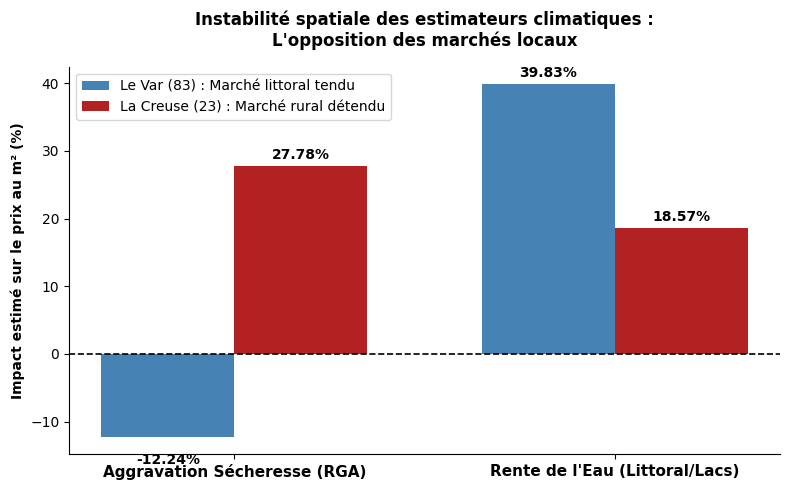

In [55]:
import matplotlib.pyplot as plt
import numpy as np

# Les variables que l'on compare
categories = ['Aggravation Sécheresse (RGA)', 'Rente de l\'Eau (Littoral/Lacs)']

# Les coefficients exacts de tes régressions (en pourcentages)
coefs_var = [-12.24, 39.83]    # Le marché en panique (Sécheresse) mais spéculatif (Mer)
coefs_creuse = [27.78, 18.57]  # Le marché aveugle (Sécheresse) et attiré par les lacs

x = np.arange(len(categories))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

# Création des barres avec des couleurs académiques (Bleu acier vs Rouge brique)
rects1 = ax.bar(x - width/2, coefs_var, width, label='Le Var (83) : Marché littoral tendu', color='steelblue')
rects2 = ax.bar(x + width/2, coefs_creuse, width, label='La Creuse (23) : Marché rural détendu', color='firebrick')

# Ligne de la rationalité (Le zéro)
ax.axhline(0, color='black', linewidth=1.2, linestyle='--')

# Mise en forme stricte
ax.set_ylabel('Impact estimé sur le prix au m² (%)', fontweight='bold')
ax.set_title('Instabilité spatiale des estimateurs climatiques :\nL\'opposition des marchés locaux', fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(categories, fontweight='bold', fontsize=11)
ax.legend()

# Retrait des bordures inutiles
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Ajout des étiquettes de valeurs sur les barres
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        va = 'bottom' if height > 0 else 'top'
        xytext = (0, 3) if height > 0 else (0, -12)
        ax.annotate(f'{height}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=xytext, textcoords="offset points",
                    ha='center', va=va, fontweight='bold', fontsize=10)

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.savefig("non_stationnarite_var_creuse.png", dpi=300, bbox_inches='tight')
plt.show()